# Milestone 5 · Notebook 2: Error Analysis, Operating Points and Calibration

**Project:** Deepfake Voice Detection for Indian Languages · Group-3

This notebook covers the three items Milestone 4 left for Milestone 5:

1. **Results by generator, attack, language, duration and speaker** on the full test sets.
2. **Calibration and operating points:** why the `valid` threshold does not transfer, how the models do at fixed false-alarm rates, and whether recalibration helps.
3. **The onset check:** does the model still use the start of a clip? F-01 rescored with the first second cut.

Inputs: `results/<run>/predictions_full.csv.gz` (every clip of `valid` and the five full test sets), the manifest from the Kaggle dataset `dsai-group3-m4-data` (version 4), and `results/F-01/predictions_trim1s.csv`. No GPU is needed; it runs in a few minutes on a CPU.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, DetCurveDisplay, RocCurveDisplay, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_curve)

ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "Milestone-5" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.metrics import eer

RESULTS = ROOT / "results"
MANIFEST = ROOT / "data" / "m4" / "manifests" / "manifest_m4.csv"   # the manifest of dataset version 4
FIGURES = ROOT / "assets" / "infographics" / "Milestone-5"
FIGURES.mkdir(parents=True, exist_ok=True)
TEST_SETS = {"test_indomain": "In-domain", "test_unseen_gen": "Unseen generators", "test_phone": "Phone channel",
             "test_itw": "In-the-Wild", "test_asvspoof": "ASVspoof eval"}
MODELS = {"F-01": "Final (seed 42)", "F-02": "Final (seed 43)", "F-03": "Final (seed 44)", "D-01": "Default config",
          "A-01": "LFCC-LCNN", "A-02": "AASIST-L"}
pd.set_option("display.width", 160)

manifest = pd.read_csv(MANIFEST, usecols=["clip_id", "duration_s", "speaker_id", "gender"], low_memory=False)
preds = {}
for run in MODELS:
    p = pd.read_csv(RESULTS / run / "predictions_full.csv.gz").merge(manifest, on="clip_id", how="left")
    p["is_fake"] = p.label.eq("fake").astype(int)
    preds[run] = p
thresholds = {run: json.load(open(RESULTS / run / "results_full.json"))["threshold"] for run in MODELS}
print({run: len(p) for run, p in preds.items()})
print("valid thresholds:", thresholds)

{'F-01': 122247, 'F-02': 122247, 'F-03': 122247, 'D-01': 122247, 'A-01': 122247, 'A-02': 122247}
valid thresholds: {'F-01': 0.99385, 'F-02': 0.01821, 'F-03': 0.95927, 'D-01': 0.50106, 'A-01': 0.54767, 'A-02': 0.41298}


## 1. Results at the `valid` threshold

The decision threshold of each model is the EER point on `valid`. Fakes are the positive class: **recall** is the share of fakes caught, **FPR** the share of real clips flagged as fake.

In [2]:
def at_threshold(p, t):
    y, yhat = p.is_fake, (p.p_fake >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"EER": 100 * eer(y, p.p_fake)[0], "accuracy": 100 * (tp + tn) / len(p),
            "precision": 100 * precision_score(y, yhat, zero_division=0), "recall": 100 * recall_score(y, yhat),
            "F1": 100 * f1_score(y, yhat), "FPR": 100 * fp / max(tn + fp, 1),
            "fakes_missed": fn, "reals_flagged": fp, "clips": len(p)}

rows = []
for run in MODELS:
    for split, name in TEST_SETS.items():
        rows.append({"model": run, "test_set": name, **at_threshold(preds[run][preds[run].split == split], thresholds[run])})
summary = pd.DataFrame(rows)
summary.round(2)

,model,test_set,EER,accuracy,precision,recall,F1,FPR,fakes_missed,reals_flagged,clips
0,F-01,In-domain,0.02,99.98,100.00,99.97,99.98,0.00,1,0,6000
1,F-01,Unseen generators,6.85,49.94,100.00,33.25,49.90,0.00,4325,0,8639
2,F-01,Phone channel,0.03,99.87,99.97,99.77,99.87,0.03,7,1,6000
3,F-01,In-the-Wild,6.91,90.51,98.90,75.46,85.61,0.50,2759,94,30066
4,F-01,ASVspoof eval,5.42,83.11,99.99,81.19,89.62,0.10,11409,7,67590
5,F-02,In-domain,0.02,99.97,99.97,99.97,99.97,0.03,1,1,6000
6,F-02,Unseen generators,9.73,60.48,100.00,47.31,64.23,0.00,3414,0,8639
7,F-02,Phone channel,0.03,99.95,99.93,99.97,99.95,0.07,1,2,6000
8,F-02,In-the-Wild,9.36,90.52,97.68,76.48,85.79,1.08,2645,204,30066
9,F-02,ASVspoof eval,16.08,73.79,99.99,70.81,82.91,0.09,17708,6,67590


In [3]:
pivot = summary.pivot(index="model", columns="test_set", values="EER")[list(TEST_SETS.values())]
print("EER (%) on the full test sets")
display(pivot.round(2))
print("Recall (% of fakes caught) at the valid threshold")
summary.pivot(index="model", columns="test_set", values="recall")[list(TEST_SETS.values())].round(1)

EER (%) on the full test sets


test_set,In-domain,Unseen generators,Phone channel,In-the-Wild,ASVspoof eval
model,,,,,
A-01,1.23,29.10,43.17,83.62,29.34
A-02,5.97,21.44,13.77,19.35,30.12
D-01,0.05,6.85,0.55,9.79,10.20
F-01,0.02,6.85,0.03,6.91,5.42
F-02,0.02,9.73,0.03,9.36,16.08
F-03,0.00,9.80,0.08,9.55,8.46


Recall (% of fakes caught) at the valid threshold


test_set,In-domain,Unseen generators,Phone channel,In-the-Wild,ASVspoof eval
model,,,,,
A-01,98.6,57.8,0.0,42.9,58.5
A-02,96.0,63.0,89.6,66.9,55.6
D-01,99.7,44.7,86.6,63.4,74.1
F-01,100.0,33.2,99.8,75.5,81.2
F-02,100.0,47.3,100.0,76.5,70.8
F-03,100.0,25.3,100.0,44.6,73.3


### Error types and threshold transfer

At the `valid` threshold, almost all errors on the hard test sets are **missed fakes**, not false alarms: the threshold learnt on `valid` (about 0.99 for the XLS-R models) is too high for generators the model has not seen. The table compares that threshold with the one that would give the EER on each test set.

In [4]:
rows = []
for run in ("F-01", "F-02", "F-03", "D-01"):
    for split, name in TEST_SETS.items():
        part = preds[run][preds[run].split == split]
        e, t_test = eer(part.is_fake, part.p_fake)
        rows.append({"model": run, "test_set": name, "valid_threshold": thresholds[run], "test_eer_threshold": t_test,
                     "missed_fakes_%": 100 * ((part.p_fake < thresholds[run]) & (part.is_fake == 1)).sum() / part.is_fake.sum(),
                     "false_alarms_%": 100 * ((part.p_fake >= thresholds[run]) & (part.is_fake == 0)).sum() / (1 - part.is_fake).sum()})
transfer = pd.DataFrame(rows)
transfer.round(4)

,model,test_set,valid_threshold,test_eer_threshold,missed_fakes_%,false_alarms_%
0,F-01,In-domain,0.9938,0.9964,0.0333,0.0000
1,F-01,Unseen generators,0.9938,0.0001,66.7541,0.0000
2,F-01,Phone channel,0.9938,0.7814,0.2333,0.0333
3,F-01,In-the-Wild,0.9938,0.0006,24.5375,0.4994
4,F-01,ASVspoof eval,0.9938,0.0012,18.8066,0.1011
5,F-02,In-domain,0.0182,0.0076,0.0333,0.0333
6,F-02,Unseen generators,0.0182,0.0008,52.6933,0.0000
7,F-02,Phone channel,0.0182,0.5404,0.0333,0.0667
8,F-02,In-the-Wild,0.0182,0.0027,23.5237,1.0838
9,F-02,ASVspoof eval,0.0182,0.0023,29.1898,0.0866


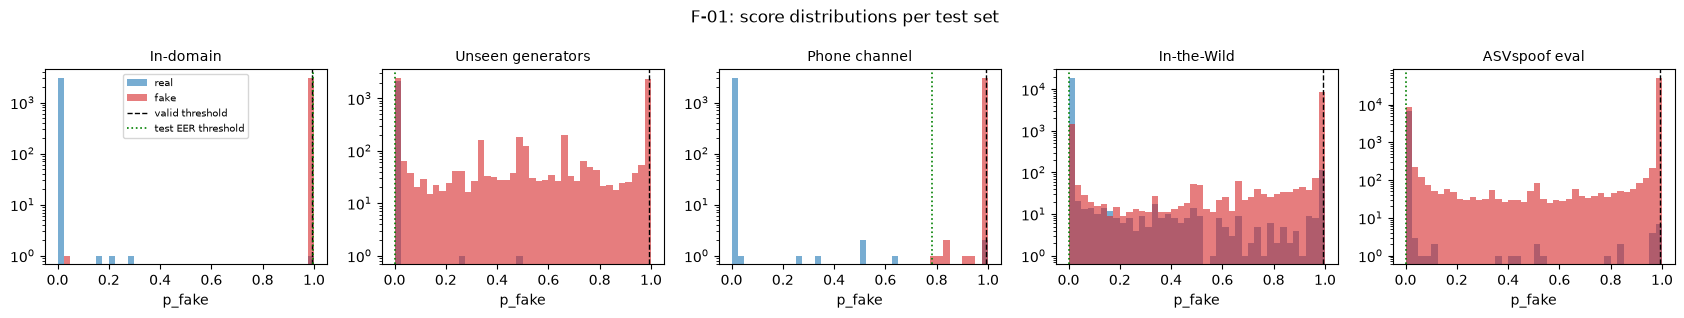

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2))
p = preds["F-01"]
for ax, (split, name) in zip(axes, TEST_SETS.items()):
    part = p[p.split == split]
    bins = np.linspace(0, 1, 41)
    ax.hist(part[part.is_fake == 0].p_fake, bins=bins, alpha=0.6, label="real", color="#1f77b4")
    ax.hist(part[part.is_fake == 1].p_fake, bins=bins, alpha=0.6, label="fake", color="#d62728")
    ax.axvline(thresholds["F-01"], color="k", ls="--", lw=1, label="valid threshold")
    ax.axvline(eer(part.is_fake, part.p_fake)[1], color="g", ls=":", lw=1.2, label="test EER threshold")
    ax.set_yscale("log")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("p_fake")
axes[0].legend(fontsize=7)
fig.suptitle("F-01: score distributions per test set")
fig.tight_layout()
fig.savefig(FIGURES / "score_distributions.png", dpi=150)
plt.show()

## 2. ROC, DET and confusion matrices

ROC and DET curves show the whole trade-off between missed fakes and false alarms, independent of the threshold. The DET plot uses normal-deviate axes, where differences at low error rates are easier to see.

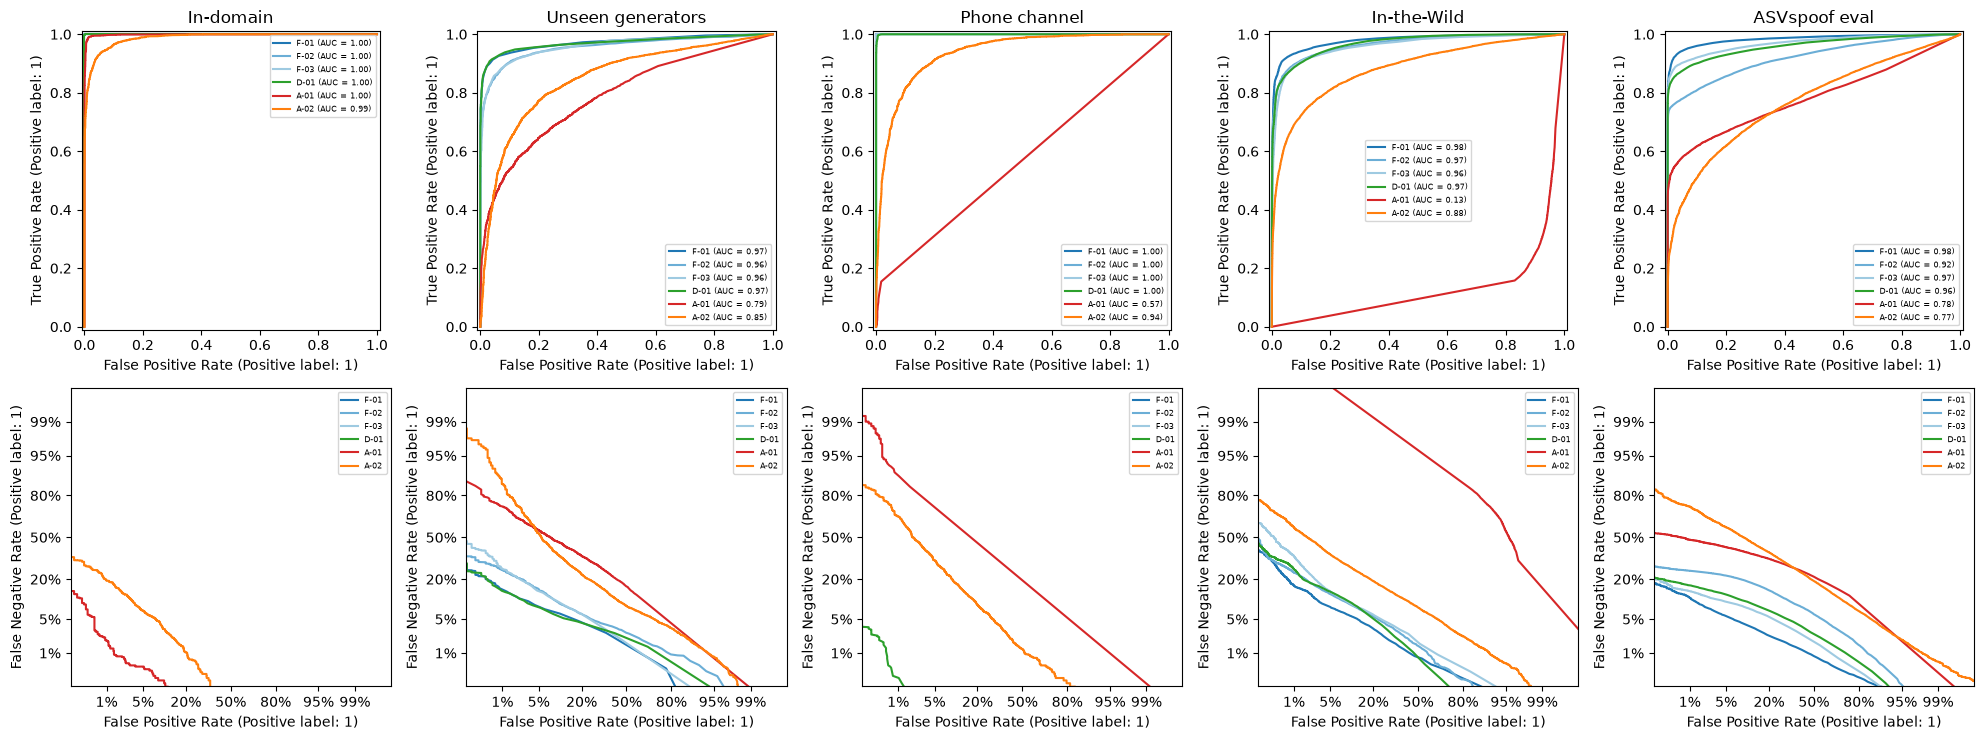

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
colors = {"F-01": "#1f77b4", "F-02": "#6baed6", "F-03": "#9ecae1", "D-01": "#2ca02c", "A-01": "#d62728", "A-02": "#ff7f0e"}
for col, (split, name) in enumerate(TEST_SETS.items()):
    for run in MODELS:
        part = preds[run][preds[run].split == split]
        RocCurveDisplay.from_predictions(part.is_fake, part.p_fake, ax=axes[0, col], name=run, curve_kwargs={"color": colors[run]})
        DetCurveDisplay.from_predictions(part.is_fake, part.p_fake, ax=axes[1, col], name=run, color=colors[run])
    axes[0, col].set_title(name)
    for ax in axes[:, col]:
        ax.legend(fontsize=6)
fig.tight_layout()
fig.savefig(FIGURES / "roc_det.png", dpi=150)
plt.show()

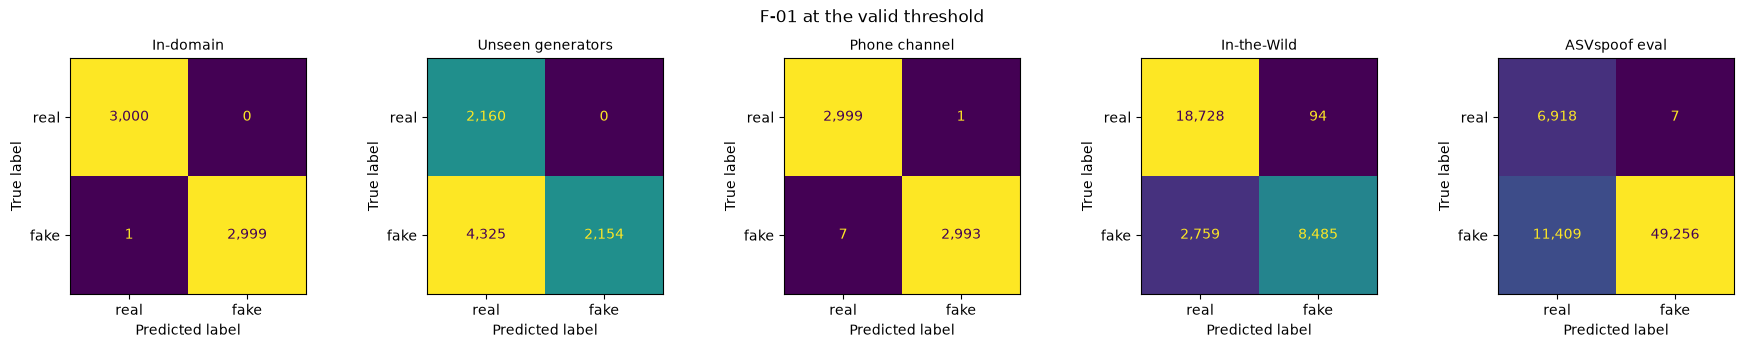

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
p = preds["F-01"]
for ax, (split, name) in zip(axes, TEST_SETS.items()):
    part = p[p.split == split]
    ConfusionMatrixDisplay.from_predictions(part.label, np.where(part.p_fake >= thresholds["F-01"], "fake", "real"),
                                            labels=["real", "fake"], ax=ax, colorbar=False, values_format=",")
    ax.set_title(name, fontsize=10)
fig.suptitle("F-01 at the valid threshold")
fig.tight_layout()
fig.savefig(FIGURES / "confusion_matrices.png", dpi=150)
plt.show()

### Operating points

A deployed detector is usually run at a fixed false-alarm rate. For each test set: the share of fakes missed when the threshold is set so that 1% or 5% of real clips are flagged (the threshold is chosen on the test set itself, so this measures the ranking, not threshold transfer).

In [8]:
def miss_at_fpr(part, target):
    fpr, tpr, _ = roc_curve(part.is_fake, part.p_fake)
    return 100 * (1 - np.interp(target, fpr, tpr))

rows = []
for run in MODELS:
    for split, name in TEST_SETS.items():
        part = preds[run][preds[run].split == split]
        rows.append({"model": run, "test_set": name, "miss@FPR1%": miss_at_fpr(part, 0.01), "miss@FPR5%": miss_at_fpr(part, 0.05)})
ops = pd.DataFrame(rows)
ops.pivot(index="model", columns="test_set", values="miss@FPR1%")[list(TEST_SETS.values())].round(1)

test_set,In-domain,Unseen generators,Phone channel,In-the-Wild,ASVspoof eval
model,,,,,
A-01,1.9,73.3,89.4,99.8,48.1
A-02,19.1,85.8,66.3,57.9,73.1
D-01,0.0,14.0,0.2,26.2,16.7
F-01,0.0,14.7,0.0,16.5,11.2
F-02,0.0,25.8,0.0,23.9,25.1
F-03,0.0,26.3,0.0,35.2,13.9


In [9]:
ops.pivot(index="model", columns="test_set", values="miss@FPR5%")[list(TEST_SETS.values())].round(1)

test_set,In-domain,Unseen generators,Phone channel,In-the-Wild,ASVspoof eval
model,,,,,
A-01,0.5,55.6,81.8,99.0,42.2
A-02,7.0,53.0,32.2,36.5,58.1
D-01,0.0,8.0,0.0,13.7,12.5
F-01,0.0,8.2,0.0,8.1,5.7
F-02,0.0,14.9,0.0,12.7,22.1
F-03,0.0,14.0,0.0,13.9,9.8


## 3. Where the errors are

### By generator and language

For each generator: the EER of its fakes against the real clips of the same test set, and the share of its fakes caught at the `valid` threshold.

In [10]:
def by_group(run, split, column):
    part = preds[run][preds[run].split == split]
    real = part[part.is_fake == 0]
    rows = []
    for g, fakes in part[part.is_fake == 1].groupby(column):
        both = pd.concat([real, fakes])
        rows.append({"model": run, column: g, "fakes": len(fakes), "EER": 100 * eer(both.is_fake, both.p_fake)[0],
                     "caught_%": 100 * (fakes.p_fake >= thresholds[run]).mean()})
    return rows

gen = pd.DataFrame([r for run in ("F-01", "F-02", "F-03", "D-01", "A-02") for r in by_group(run, "test_unseen_gen", "generator")])
display(gen.pivot(index="generator", columns="model", values="EER").round(2))
gen.pivot(index="generator", columns="model", values="caught_%").round(1)

model,A-02,D-01,F-01,F-02,F-03
generator,,,,,
indic-parler-tts,18.99,1.55,3.06,8.01,8.84
indicf5,34.42,13.43,15.60,15.90,12.11
mms-tts,9.26,3.94,3.59,5.65,8.77


model,A-02,D-01,F-01,F-02,F-03
generator,,,,,
indic-parler-tts,65.4,63.3,44.0,50.3,35.5
indicf5,31.6,32.5,16.9,30.3,11.0
mms-tts,92.1,38.2,38.8,61.3,29.3


In [11]:
rows = []
for run in ("F-01", "D-01"):
    for split in ("test_unseen_gen", "test_indomain", "test_phone"):
        part = preds[run][preds[run].split == split]
        for lang, g in part.groupby("language"):
            for gen_name, fakes in g[g.is_fake == 1].groupby("generator"):
                both = pd.concat([g[g.is_fake == 0], fakes])
                rows.append({"model": run, "test_set": TEST_SETS[split], "language": lang, "generator": gen_name,
                             "EER": 100 * eer(both.is_fake, both.p_fake)[0], "caught_%": 100 * (fakes.p_fake >= thresholds[run]).mean()})
lang = pd.DataFrame(rows)
lang[lang.test_set == "Unseen generators"].pivot(index=["generator", "language"], columns="model", values=["EER", "caught_%"]).round(1)

EER       caught_%      
model                      D-01  F-01     D-01  F-01
generator        language                           
indic-parler-tts hi         0.8   1.7     54.3  54.9
                 ta         1.2   2.2     76.4  47.1
                 te         2.5   3.2     59.2  30.2
indicf5          hi        14.7  17.2     15.1  11.5
                 ta        21.8  16.0     38.1  23.9
                 te         8.8  10.4     44.4  15.1
mms-tts          hi         0.7   0.1     68.1  84.9
                 ta         1.9   2.2     40.7  25.0
                 te         6.5   5.0      6.0   6.7

### By ASVspoof attack

Each attack's fakes against all bona fide clips of the ASVspoof evaluation set. A16 and A19 are the same systems as the training attacks A04 and A06; the other eleven are new.

model,A-02,D-01,F-01,F-02,F-03
attack,,,,,
A07,34.93,4.79,2.45,18.13,8.03
A08,7.29,1.31,0.26,7.55,0.59
A09,2.11,0.30,0.03,0.86,0.20
A10,39.41,38.83,19.67,49.10,33.70
A11,37.91,21.11,12.51,30.68,14.55
A12,44.76,13.03,5.61,22.37,12.42
A13,47.04,0.71,1.40,1.99,0.54
A14,15.43,2.27,0.42,10.87,0.95
A15,12.52,4.49,1.97,17.37,4.27


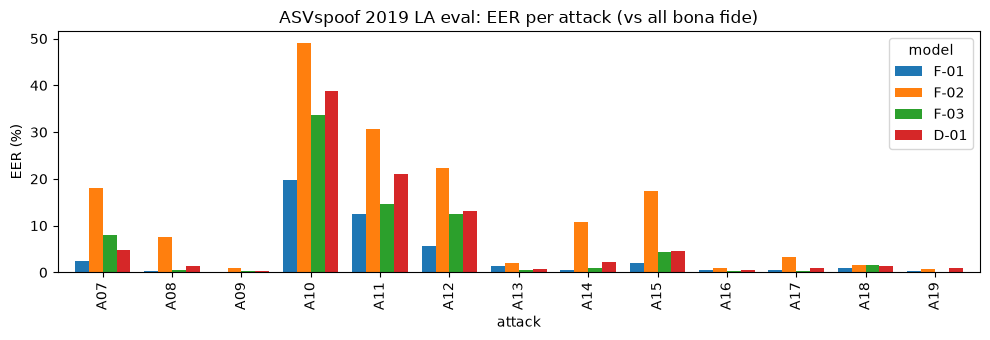

In [12]:
att = pd.DataFrame([r for run in ("F-01", "F-02", "F-03", "D-01", "A-02") for r in by_group(run, "test_asvspoof", "generator")])
att = att.rename(columns={"generator": "attack"})
attack_eer = att.pivot(index="attack", columns="model", values="EER")
display(attack_eer.round(2))
fig, ax = plt.subplots(figsize=(10, 3.5))
attack_eer[["F-01", "F-02", "F-03", "D-01"]].plot.bar(ax=ax, width=0.8)
ax.set_ylabel("EER (%)")
ax.set_title("ASVspoof 2019 LA eval: EER per attack (vs all bona fide)")
fig.tight_layout()
fig.savefig(FIGURES / "asvspoof_attacks.png", dpi=150)
plt.show()

### By clip duration

Shorter clips give the model fewer windows to average over. EER per duration bin on the two English sets, where durations vary most.

In [13]:
bins = [1, 2, 3, 4, 6, 10, 60]
rows = []
for run in ("F-01", "D-01", "A-02"):
    for split in ("test_itw", "test_asvspoof"):
        part = preds[run][preds[run].split == split].copy()
        part["duration"] = pd.cut(part.duration_s, bins, right=False)
        for d, g in part.groupby("duration", observed=True):
            if g.is_fake.nunique() == 2 and len(g) >= 200:
                rows.append({"model": run, "test_set": TEST_SETS[split], "duration_s": str(d), "clips": len(g),
                             "EER": 100 * eer(g.is_fake, g.p_fake)[0]})
dur = pd.DataFrame(rows)
dur.pivot(index=["test_set", "duration_s"], columns="model", values="EER").round(2)

model                      A-02   D-01   F-01
test_set      duration_s                     
ASVspoof eval [1, 2)      32.35  10.50   7.48
              [2, 3)      31.36   9.75   4.69
              [3, 4)      31.36   9.60   3.70
              [4, 6)      33.27   8.40   3.97
              [6, 10)     30.74   7.68   6.32
In-the-Wild   [1, 2)      23.00  20.82  14.95
              [10, 60)    18.22   8.98   5.51
              [2, 3)      20.80  13.09   8.97
              [3, 4)      19.40   6.58   4.68
              [4, 6)      16.82   3.52   3.07
              [6, 10)     15.43   3.16   3.06

### In-the-Wild speakers

In-the-Wild has 54 public figures, each with real and fake clips. EER per speaker (speakers with at least 50 real and 50 fake clips), F-01.

In [14]:
part = preds["F-01"][preds["F-01"].split == "test_itw"]
rows = []
for spk, g in part.groupby("speaker_id"):
    if (g.is_fake == 0).sum() >= 50 and (g.is_fake == 1).sum() >= 50:
        rows.append({"speaker": spk, "clips": len(g), "EER": 100 * eer(g.is_fake, g.p_fake)[0],
                     "caught_%": 100 * (g[g.is_fake == 1].p_fake >= thresholds["F-01"]).mean(),
                     "reals_flagged_%": 100 * (g[g.is_fake == 0].p_fake >= thresholds["F-01"]).mean()})
spk = pd.DataFrame(rows).sort_values("EER")
print(f"{len(spk)} speakers; EER median {spk.EER.median():.1f}%, range {spk.EER.min():.1f}-{spk.EER.max():.1f}%")
pd.concat([spk.head(5), spk.tail(5)]).round(1)

31 speakers; EER median 3.6%, range 0.0-18.0%


,speaker,clips,EER,caught_%,reals_flagged_%
4,Alexandria Ocasio-Cortez,366,0.0,85.0,0.0
9,Bill Burr,179,0.0,98.2,0.0
18,Gilbert Gottfried,200,0.0,100.0,0.0
8,Bernie Sanders,2738,0.2,99.5,0.0
12,Christopher Hitchens,1246,0.2,99.8,0.3
15,FDR,468,11.4,26.4,0.7
19,JFK,658,13.1,62.2,1.8
7,Barack Obama,3378,14.3,33.1,0.1
26,Nelson Mandela,364,16.3,26.7,0.0
2,Alan Watts,283,18.0,73.9,9.8


## 4. Calibration

The XLS-R models are overconfident: on `valid` almost every clip scores near 0 or 1. Expected calibration error (ECE, 15 equal-width bins) per test set measures how far `p_fake` is from the observed share of fakes.

Two recalibrations are compared, both a logistic map on logit(p_fake) (Platt scaling), which keeps the ranking and so cannot change the EER:
- **fitted on `valid`**: the usual approach, and
- **fitted on 10% of the target test set** (seeded, stratified), evaluated on the other 90%: what a small labelled sample from the deployment domain buys.

In [15]:
def ece(y, p, bins=15):
    y, p = np.asarray(y), np.asarray(p)
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1)
    return 100 * sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any())

def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

def platt(fit_part):
    return LogisticRegression(C=1.0).fit(logit(fit_part.p_fake), fit_part.is_fake)

rows = []
for run in ("F-01", "D-01", "A-02"):
    p = preds[run]
    on_valid = platt(p[p.split == "valid"])
    for split, name in TEST_SETS.items():
        part = p[p.split == split]
        fit = part.groupby("is_fake", group_keys=False).sample(frac=0.1, random_state=0)
        rest = part.drop(fit.index)
        on_target = platt(fit)
        acc = lambda q: 100 * ((q >= 0.5) == rest.is_fake).mean()
        q_valid = on_valid.predict_proba(logit(rest.p_fake))[:, 1]
        q_target = on_target.predict_proba(logit(rest.p_fake))[:, 1]
        rows.append({"model": run, "test_set": name,
                     "ECE_raw": ece(rest.is_fake, rest.p_fake), "ECE_valid_fit": ece(rest.is_fake, q_valid),
                     "ECE_10pct_target": ece(rest.is_fake, q_target),
                     "acc_valid_threshold": 100 * ((rest.p_fake >= thresholds[run]) == rest.is_fake).mean(),
                     "acc_10pct_target": acc(q_target)})
calib = pd.DataFrame(rows)
calib.round(2)

,model,test_set,ECE_raw,ECE_valid_fit,ECE_10pct_target,acc_valid_threshold,acc_10pct_target
0,F-01,In-domain,0.04,0.03,0.03,99.98,99.96
1,F-01,Unseen generators,37.80,43.84,2.91,49.84,92.89
2,F-01,Phone channel,0.09,0.09,0.10,99.85,99.93
3,F-01,In-the-Wild,6.29,7.28,3.95,90.58,93.79
4,F-01,ASVspoof eval,14.59,15.31,1.26,83.09,95.76
5,D-01,In-domain,0.20,0.22,0.14,99.85,99.91
6,D-01,Unseen generators,41.32,40.01,2.45,58.46,93.25
7,D-01,Phone channel,7.53,7.31,0.84,93.30,99.00
8,D-01,In-the-Wild,13.74,13.19,4.64,86.07,91.30
9,D-01,ASVspoof eval,23.23,22.92,0.37,76.77,92.49


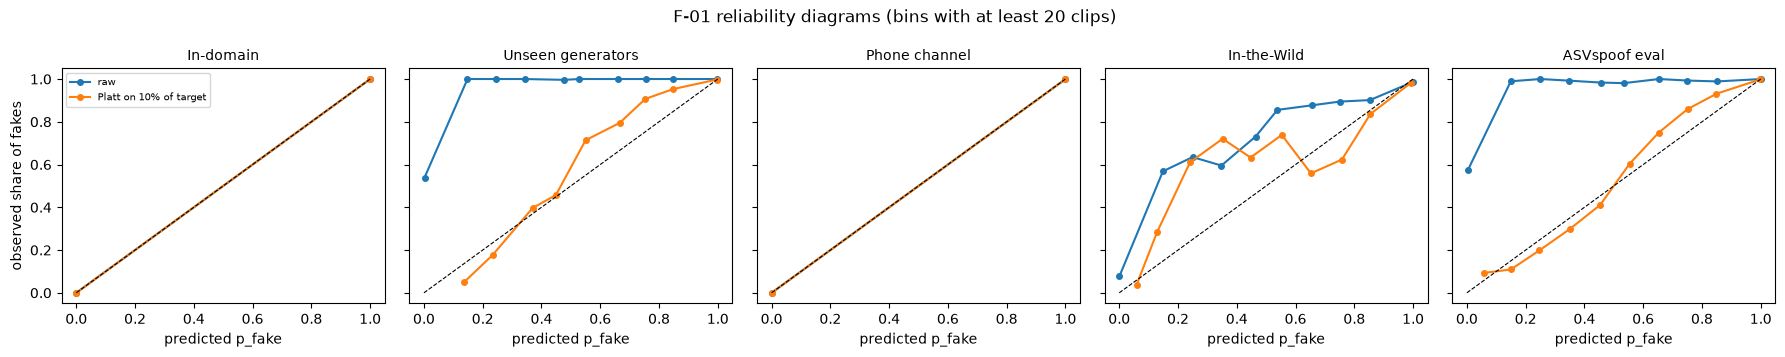

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
p = preds["F-01"]
on_valid = platt(p[p.split == "valid"])
for ax, (split, name) in zip(axes, TEST_SETS.items()):
    part = p[p.split == split]
    fit = part.groupby("is_fake", group_keys=False).sample(frac=0.1, random_state=0)
    rest = part.drop(fit.index)
    curves = {"raw": rest.p_fake.to_numpy(), "Platt on 10% of target": platt(fit).predict_proba(logit(rest.p_fake))[:, 1]}
    for label, q in curves.items():
        edges = np.linspace(0, 1, 11)
        idx = np.clip(np.digitize(q, edges) - 1, 0, 9)
        xs = [q[idx == b].mean() for b in range(10) if (idx == b).sum() >= 20]
        ys = [rest.is_fake.to_numpy()[idx == b].mean() for b in range(10) if (idx == b).sum() >= 20]
        ax.plot(xs, ys, "o-", label=label, ms=4)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("predicted p_fake")
axes[0].set_ylabel("observed share of fakes")
axes[0].legend(fontsize=7)
fig.suptitle("F-01 reliability diagrams (bins with at least 20 clips)")
fig.tight_layout()
fig.savefig(FIGURES / "reliability.png", dpi=150)
plt.show()

## 5. Onset check

Milestone 4's explanation view showed F-01 reacting to the first second of a real clip. After the click was removed (Milestone 4, Section 2.4), the start of real recordings might still carry a cue such as room noise. The final models were rescored on `valid` and the Milestone-4 test sample with the **first second cut** from every clip that is at least 2 s long (shorter clips are left out of this comparison). If the model relied on the onset, the EER would rise and real clips would move towards "fake" or "real" as a group.

In [17]:
rows = []
onset_runs = [r for r in ("F-01", "F-02", "F-03") if (RESULTS / r / "predictions_trim1s.csv").exists()]
print("rescored with the first second cut:", onset_runs)
for run in onset_runs:
    t = json.load(open(RESULTS / run / "results.json"))["threshold"]
    m = (pd.read_csv(RESULTS / run / "predictions.csv")
         .merge(pd.read_csv(RESULTS / run / "predictions_trim1s.csv")[["clip_id", "p_fake"]], on="clip_id", suffixes=("", "_trim"))
         .merge(manifest[["clip_id", "duration_s"]], on="clip_id"))
    m = m[m.duration_s >= 2]
    m["is_fake"] = m.label.eq("fake").astype(int)
    for split, g in m.groupby("split", sort=False):
        if g.is_fake.nunique() < 2:
            continue
        rows.append({"model": run, "split": split, "clips": len(g), "EER_whole": 100 * eer(g.is_fake, g.p_fake)[0],
                     "EER_first_1s_cut": 100 * eer(g.is_fake, g.p_fake_trim)[0],
                     "real_mean_shift": (g[g.is_fake == 0].p_fake_trim - g[g.is_fake == 0].p_fake).mean(),
                     "fake_mean_shift": (g[g.is_fake == 1].p_fake_trim - g[g.is_fake == 1].p_fake).mean(),
                     "decisions_changed_%": 100 * ((g.p_fake >= t) != (g.p_fake_trim >= t)).mean()})
onset = pd.DataFrame(rows)
onset.round(3)

rescored with the first second cut: ['F-01', 'F-02']


,model,split,clips,EER_whole,EER_first_1s_cut,real_mean_shift,fake_mean_shift,decisions_changed_%
0,F-01,valid,3525,0.000,0.000,0.000,0.000,0.000
1,F-01,test_indomain,1000,0.000,0.000,0.000,0.000,0.000
2,F-01,test_unseen_gen,1000,6.500,6.700,0.002,-0.016,4.900
3,F-01,test_phone,1000,0.000,0.000,0.001,0.001,0.200
4,F-01,test_itw,734,4.903,6.412,0.007,-0.017,4.496
5,F-01,test_asvspoof,519,5.008,7.315,0.001,-0.041,4.046
6,F-02,valid,3525,0.028,0.142,-0.000,-0.004,0.142
7,F-02,test_indomain,1000,0.000,0.000,-0.000,0.001,0.000
8,F-02,test_unseen_gen,1000,9.200,7.900,-0.000,-0.006,4.700
9,F-02,test_phone,1000,0.000,0.000,-0.000,0.001,0.000


## 6. Summary

The figures are saved in `assets/infographics/Milestone-5/`; the interpretation is in the Milestone-5 report.

In [18]:
print("EER (%), full test sets:"); print(pivot.round(2).to_string()); print()
print("F-01 missed fakes at the valid threshold (%):", transfer[transfer.model == "F-01"].set_index("test_set")["missed_fakes_%"].round(1).to_dict())
print("Unseen generators, F-01 EER by generator:", gen[gen.model == "F-01"].set_index("generator").EER.round(2).to_dict())
print("ASVspoof hardest attacks (F-01):", attack_eer["F-01"].sort_values(ascending=False).head(3).round(1).to_dict())
print("Calibration, F-01 ECE raw -> 10% target fit:", calib[calib.model == "F-01"].set_index("test_set")[["ECE_raw", "ECE_10pct_target"]].round(1).to_dict("index"))
print("Onset check:"); print(onset.round(3).to_string(index=False))

EER (%), full test sets:
test_set  In-domain  Unseen generators  Phone channel  In-the-Wild  ASVspoof eval
model                                                                            
A-01           1.23              29.10          43.17        83.62          29.34
A-02           5.97              21.44          13.77        19.35          30.12
D-01           0.05               6.85           0.55         9.79          10.20
F-01           0.02               6.85           0.03         6.91           5.42
F-02           0.02               9.73           0.03         9.36          16.08
F-03           0.00               9.80           0.08         9.55           8.46

F-01 missed fakes at the valid threshold (%): {'In-domain': 0.0, 'Unseen generators': 66.8, 'Phone channel': 0.2, 'In-the-Wild': 24.5, 'ASVspoof eval': 18.8}
Unseen generators, F-01 EER by generator: {'indic-parler-tts': 3.06, 'indicf5': 15.6, 'mms-tts': 3.59}
ASVspoof hardest attacks (F-01): {'A10': 19.7, 'A11': 12.